In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

In [13]:
# 1 балл (сумма 1)

# Скачать olimpic.csv.zip (прочитать прямо архив стандартным способом)
olimpic = pd.read_csv(r'/Users/sofkatulyakova/Downloads/olimpic.csv.zip')

# Скачать region.csv
region = pd.read_csv('region.csv')
# Срезать данные по ЛЕТНЕЙ олимпмаде, в дальнейшем использовать только данные по ЛЕТНЕЙ олимпиаде
summer_olimpic = olimpic[olimpic['Season'] == "Summer"]
print(summer_olimpic)


            ID                                Name Sex   Age  Height  Weight  \
0            1                           A Dijiang   M  24.0   180.0    80.0   
1            2                            A Lamusi   M  23.0   170.0    60.0   
2            3                 Gunnar Nielsen Aaby   M  24.0     NaN     NaN   
3            4                Edgar Lindenau Aabye   M  34.0     NaN     NaN   
26           8  Cornelia "Cor" Aalten (-Strannood)   F  18.0   168.0     NaN   
...        ...                                 ...  ..   ...     ...     ...   
271106  135565            Fernando scar Zylberberg   M  27.0   168.0    76.0   
271107  135566          James Francis "Jim" Zylker   M  21.0   175.0    75.0   
271108  135567        Aleksandr Viktorovich Zyuzin   M  24.0   183.0    72.0   
271109  135567        Aleksandr Viktorovich Zyuzin   M  28.0   183.0    72.0   
271110  135568              Olga Igorevna Zyuzkova   F  33.0   171.0    69.0   

                  Team  NOC        Game

In [ ]:
# 1 балл (сумма 2) 
# Слить две таблицы в одну, следующим образом - к olympics добавить 
# два столбца (region, notes), ключевой столбец NOC
merged_data = pd.merge(
    olimpic,                 
    region[['NOC', 'region', 'notes']],  
    on='NOC',                   
    how='left'                   
)
print(merged_data)

            ID                      Name Sex   Age  Height  Weight  \
0            1                 A Dijiang   M  24.0   180.0    80.0   
1            2                  A Lamusi   M  23.0   170.0    60.0   
2            3       Gunnar Nielsen Aaby   M  24.0     NaN     NaN   
3            4      Edgar Lindenau Aabye   M  34.0     NaN     NaN   
4            5  Christine Jacoba Aaftink   F  21.0   185.0    82.0   
...        ...                       ...  ..   ...     ...     ...   
271111  135569                Andrzej ya   M  29.0   179.0    89.0   
271112  135570                  Piotr ya   M  27.0   176.0    59.0   
271113  135570                  Piotr ya   M  27.0   176.0    59.0   
271114  135571        Tomasz Ireneusz ya   M  30.0   185.0    96.0   
271115  135571        Tomasz Ireneusz ya   M  34.0   185.0    96.0   

                  Team  NOC        Games  Year  Season            City  \
0                China  CHN  1992 Summer  1992  Summer       Barcelona   
1          

In [ ]:
# 1 балл (сумма 3) 
# найти количество золотых, серебрянных и бронзовых медалей для летней олимпиады 
# реультат DataFrame
# индексы тип медали по порядку от золотой к бронзовой

medal_counts = (
    merged_data['Medal']
    .value_counts()
    .loc[['Gold', 'Silver', 'Bronze']] 
    .rename_axis('Medal')  
    .to_frame('Count')  
)

print(medal_counts)

        Count
Medal        
Gold    13372
Silver  13116
Bronze  13295


In [ ]:
# 1 балл (сумма 4) 
# Сколько медалистов имеют рост выше 190 см и вес больше 100 кг?
# ответ в виде числа
# Фильтруем данные по условиям роста и веса
height_weight = merged_data[
    (merged_data['Height'] > 190) & (merged_data['Weight'] > 100)
]
count = len(height_weight)
print(count)

# и указать виды спорта (Sport) и количество медалей, ответ в виде Series
sport_medal_counts = height_weight['Sport'].value_counts()
print(sport_medal_counts)


2683
Sport
Athletics           731
Basketball          571
Handball            202
Water Polo          198
Rowing              190
Judo                141
Wrestling           128
Volleyball           91
Bobsleigh            77
Ice Hockey           59
Sailing              55
Boxing               39
Swimming             38
Weightlifting        33
Shooting             32
Baseball             24
Beach Volleyball     19
Rugby Sevens         14
Canoeing             12
Taekwondo             8
Cycling               6
Archery               5
Alpine Skiing         4
Tennis                2
Freestyle Skiing      1
Fencing               1
Tug-Of-War            1
Luge                  1
Name: count, dtype: int64


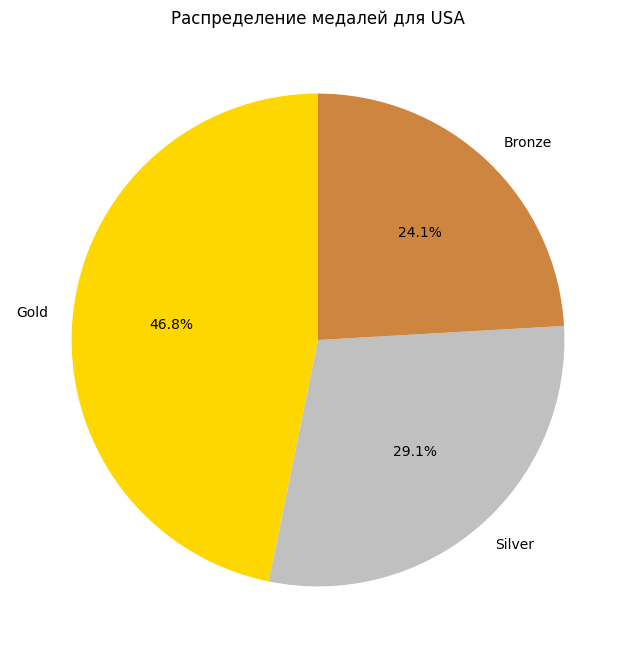

In [34]:
# 1  балл (сумма 5)
# Построить круговую диаграмму распределения типов медалей (Gold/Silver/Bronze) для команды с наибольшим числом медалистов из задания 4
# команда - страна у которой больше всего побед в виде спорта из задания 4
top_country = height_weight['NOC'].value_counts().index[0]

country_medals = merged_data[merged_data['NOC'] == top_country]

medal_distribution = country_medals['Medal'].value_counts()

medal_order = ['Gold', 'Silver', 'Bronze']
medal_distribution = medal_distribution.reindex(medal_order)

# круговая диаграмма
plt.figure(figsize=(8, 8))
plt.pie(medal_distribution, 
        labels=medal_distribution.index,
        autopct='%1.1f%%',
        startangle=90,
        colors=['gold', 'silver', 'peru'])
plt.title(f'Распределение медалей для {top_country}')
plt.show()

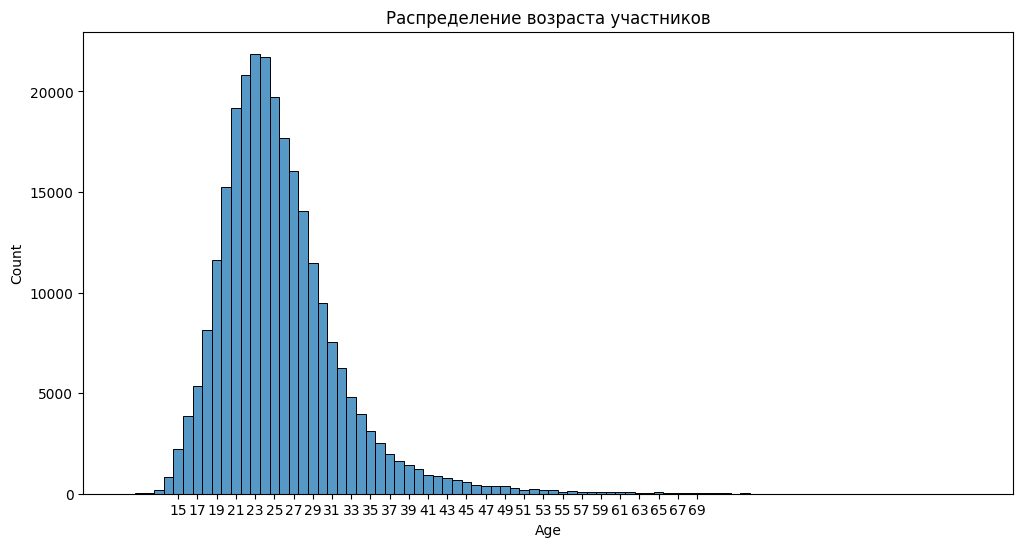

In [37]:
# 1  балл (сумма 6)
# построить КОРРЕКТНОЕ распределения УЧАСТНИКОВ летних олимпийских игр от их возраста
# внимание: возраст обязательно - целые числа на оси x


plt.figure(figsize=(12, 6))
sns.histplot(data=merged_data, 
             x='Age',
             bins=range(15, 70),
             discrete=True) 

plt.title('Распределение возраста участников')
plt.xticks(range(15, 70, 2))  # Частые метки
plt.show()

In [8]:
# 1 балл (сумма 7) 
# в виде точек визуализировать зависимость роста(ось x) и веса(ось y) 
# для всех ЧЕМПИОНОВ и выделить точки для ЧЕМПИОНОВ атлетики (Athletics)

In [ ]:
# 1 балл (сумма 8) 
# создать отдельную таблицу для летних олимпийских игр с 1950 с 1980 в которой

# Заменить медали на баллы: `Gold: 10`, `Silver: 5`, `Bronze: 2`

            ID                                 Name Sex   Age  Height  Weight  \
2            3                  Gunnar Nielsen Aaby   M  24.0     NaN     NaN   
3            4                 Edgar Lindenau Aabye   M  34.0     NaN     NaN   
26           8   Cornelia "Cor" Aalten (-Strannood)   F  18.0   168.0     NaN   
27           8   Cornelia "Cor" Aalten (-Strannood)   F  18.0   168.0     NaN   
29          10       Einar Ferdinand "Einari" Aalto   M  26.0     NaN     NaN   
...        ...                                  ...  ..   ...     ...     ...   
271080  135553  Galina Ivanovna Zybina (-Fyodorova)   F  33.0   168.0    80.0   
271100  135561                        Frantiek Zyka   M  26.0     NaN     NaN   
271101  135562                           Milan Zyka   M  24.0   173.0    68.0   
271107  135566           James Francis "Jim" Zylker   M  21.0   175.0    75.0   
271111  135569                           Andrzej ya   M  29.0   179.0    89.0   

                  Team  NOC

In [10]:
# 1 балл (сумма 9)
# найти СПИСОК 5 команд (region) набравщих суммарно больше всех баллов в медальном зачете

In [11]:
# 1 балл (сумма 10)
# Найти в каком году (индекс) и для каждой страны из списка (колонки) набрано медальных баллов